# Evasão de alunos: Gower + Leiden e GNN + Associação

Dataset: *Predict students' dropout and academic success* (`data.csv`). Foco: **Dropout × Graduate (aprovado)**.

| Parte | O que faz |
|---|---|
| **1. Gower + Leiden** | Distância de Gower → grafo k-NN → comunidades (Leiden) → visualização |
| **2. GNN + Associação** | GNN (GraphSAGE/GCN) treinada em 80% e testada nos 20% escondidos → regras de associação sobre as previsões |
| **3. Teste 80/20 repetido** | Repete o 80/20 várias vezes e compara GCN × GraphSAGE × regressão logística (sem grafo) |

**Como usar:** deixe o `data.csv` na mesma pasta do notebook e rode as células em ordem (*Run All*).

In [23]:
# Rode uma vez se faltar alguma biblioteca (remova o #):
#%pip install python-igraph leidenalg gower mlxtend torch torch_geometric scikit-learn pandas numpy matplotlib

## 0. Configuração e imports

In [24]:
import copy
import os
import random
import warnings

import gower
import igraph as ig
import leidenalg
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from IPython.display import Image, display
from matplotlib.collections import LineCollection
from mlxtend.frequent_patterns import apriori, association_rules
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, adjusted_rand_score, classification_report,
                             confusion_matrix, f1_score, normalized_mutual_info_score,
                             roc_auc_score)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from torch_geometric.data import Data
from torch_geometric.nn import GCNConv, SAGEConv

warnings.filterwarnings("ignore")

In [25]:
# ===== PARÂMETROS (altere aqui) =====
CSV = "data.csv"
PASTA_SAIDA = "resultados"
INCLUIR_ENROLLED = False   # True = mantém a 3ª classe (Enrolled)
K = 15                     # vizinhos do grafo k-NN
RESOLUCAO = 1.0            # resolução do Leiden (maior = mais comunidades)
ARQUITETURA = "sage"       # "sage" (GraphSAGE) ou "gcn"
REPETICOES = 10            # nº de divisões 80/20 no teste repetido
SEED = 42

## 1. Carregar os dados

In [26]:
def carregar_dados(caminho, incluir_enrolled=False):
    # sep=None detecta ; ou , ; utf-8-sig remove o BOM do Excel
    df = pd.read_csv(caminho, sep=None, engine="python", encoding="utf-8-sig")
    df.columns = df.columns.str.replace(r"\s+", " ", regex=True).str.strip()
    if not incluir_enrolled:  # foco: Dropout x Graduate (aprovado)
        df = df[df["Target"] != "Enrolled"]
    return df.reset_index(drop=True)

In [27]:
df = carregar_dados(CSV, INCLUIR_ENROLLED)
print(f"Dataset: {df.shape[0]} alunos, {df.shape[1] - 1} atributos")
print(df["Target"].value_counts().to_string())

Dataset: 3630 alunos, 36 atributos
Target
Graduate    2209
Dropout     1421


## 2. Gower + Leiden

A distância de Gower aceita atributos numéricos e categóricos misturados. Cada aluno se liga aos `K` mais parecidos (grafo k-NN ponderado) e o Leiden agrupa o grafo em comunidades. O rótulo (Dropout/Graduate) **não** entra no cálculo: ele só é usado depois, para avaliar as comunidades.

### Funções

In [28]:
CORES_ALVO = {"Dropout": "#d62728", "Graduate": "#2ca02c", "Enrolled": "#1f77b4"}

# Colunas que são códigos nominais (não têm ordem). As demais são numéricas.
COLUNAS_CATEGORICAS = [
    "Marital status", "Application mode", "Course",
    "Daytime/evening attendance", "Previous qualification", "Nacionality",
    "Mother's qualification", "Father's qualification",
    "Mother's occupation", "Father's occupation", "Displaced",
    "Educational special needs", "Debtor", "Tuition fees up to date",
    "Gender", "Scholarship holder", "International",
]

#### 1. Distância de Gower

In [29]:
def calcular_distancia_gower(df, coluna_alvo="Target"):
    """Matriz (n x n) de distância de Gower. O alvo NÃO entra no cálculo."""
    X = df.drop(columns=[coluna_alvo]).copy()
    eh_cat = [c in COLUNAS_CATEGORICAS for c in X.columns]
    for c, cat in zip(X.columns, eh_cat):
        X[c] = X[c].astype(str) if cat else X[c].astype(float)
    return gower.gower_matrix(X, cat_features=eh_cat).astype(np.float32)

#### 2. Grafo k-NN

In [30]:
def construir_grafo_knn(dist, k=15):
    """Grafo não direcionado: cada aluno liga-se aos k mais parecidos.
    Peso da aresta = similaridade = 1 - distância."""
    n = dist.shape[0]
    d = dist.copy()
    np.fill_diagonal(d, np.inf)
    vizinhos = np.argpartition(d, k, axis=1)[:, :k]

    arestas = {}
    for i in range(n):
        for j in vizinhos[i]:
            a, b = (i, int(j)) if i < int(j) else (int(j), i)
            arestas[(a, b)] = max(1.0 - float(dist[i, j]), 1e-6)

    g = ig.Graph(n=n, edges=list(arestas.keys()))
    g.es["weight"] = list(arestas.values())
    return g

#### 3. Leiden

In [31]:
def detectar_comunidades(g, resolucao=1.0, seed=42):
    particao = leidenalg.find_partition(
        g,
        leidenalg.RBConfigurationVertexPartition,
        weights="weight",
        resolution_parameter=resolucao,
        seed=seed,
    )
    return np.array(particao.membership)

#### 4. Avaliação

In [32]:
def avaliar_comunidades(g, membership, rotulos):
    tabela = pd.crosstab(membership, rotulos)
    tabela.index.name = "comunidade"
    tabela.columns.name = None
    tabela["tamanho"] = tabela.sum(axis=1)
    pureza = tabela.drop(columns="tamanho").max(axis=1).sum() / len(rotulos)
    metricas = {
        "n_comunidades": int(len(np.unique(membership))),
        "modularidade": float(g.modularity(list(membership), weights="weight")),
        "pureza": float(pureza),
        "ARI": float(adjusted_rand_score(rotulos, membership)),
        "NMI": float(normalized_mutual_info_score(rotulos, membership)),
    }
    return metricas, tabela

#### 5. Visualização

In [33]:
def _desenhar_grafo(ax, g, pos, cores, titulo):
    segmentos = [(pos[a], pos[b]) for a, b in g.get_edgelist()]
    ax.add_collection(LineCollection(segmentos, colors="#999999",
                                     linewidths=0.2, alpha=0.12, zorder=1))
    ax.scatter(pos[:, 0], pos[:, 1], c=cores, s=6, linewidths=0, zorder=2)
    ax.set_title(titulo, fontsize=12)
    ax.set_aspect("equal")
    ax.axis("off")


def visualizar_comunidades(g, membership, rotulos, tabela, caminho_png, seed=42):
    # Layout ilustrativo: reforça as arestas internas de cada comunidade para
    # que os grupos fiquem visualmente separados (não altera o grafo real).
    random.seed(seed)  # igraph usa o gerador do Python -> layout reprodutível
    g_aux = g.copy()
    w = np.array(g.es["weight"])
    intra = np.array([membership[a] == membership[b] for a, b in g.get_edgelist()])
    g_aux.es["weight"] = list(np.where(intra, 5 * w ** 2, 0.05 * w))
    pos = np.array(g_aux.layout_fruchterman_reingold(weights="weight", niter=300,
                                                     seed=None).coords)

    cmap = plt.get_cmap("tab20")
    cores_com = [cmap(c % 20) for c in membership]
    cores_alvo = [CORES_ALVO.get(r, "#7f7f7f") for r in rotulos]

    fig = plt.figure(figsize=(20, 7))
    ax1 = fig.add_subplot(1, 3, 1)
    _desenhar_grafo(ax1, g, pos, cores_com,
                    f"Comunidades de Leiden ({tabela.shape[0]})")
    for c in np.unique(membership):
        centro = pos[membership == c].mean(axis=0)
        ax1.text(*centro, str(c), fontsize=11, weight="bold", ha="center",
                 va="center", bbox=dict(boxstyle="round,pad=0.2", fc="white", alpha=0.7))

    ax2 = fig.add_subplot(1, 3, 2)
    _desenhar_grafo(ax2, g, pos, cores_alvo, "Mesmo grafo colorido pela situação real")
    for nome, cor in CORES_ALVO.items():
        if nome in set(rotulos):
            ax2.scatter([], [], c=cor, label=nome, s=30)
    ax2.legend(loc="lower right")

    ax3 = fig.add_subplot(1, 3, 3)
    prop = tabela.drop(columns="tamanho")
    prop = prop.div(prop.sum(axis=1), axis=0) * 100
    prop = prop[[c for c in ["Dropout", "Enrolled", "Graduate"] if c in prop.columns]]
    prop.plot(kind="bar", stacked=True, ax=ax3,
              color=[CORES_ALVO[c] for c in prop.columns], width=0.8)
    ax3.set_title("Composição de cada comunidade (%)", fontsize=12)
    ax3.set_xlabel("Comunidade")
    ax3.set_ylabel("% de alunos")
    ax3.legend(loc="lower center", bbox_to_anchor=(0.5, -0.25), ncol=3)
    for i, tam in enumerate(tabela["tamanho"]):
        ax3.text(i, 101, f"n={tam}", ha="center", fontsize=8)
    ax3.set_ylim(0, 108)

    plt.tight_layout()
    fig.savefig(caminho_png, dpi=150)
    plt.close(fig)

#### Função principal do módulo

In [34]:
def executar_leiden(df, pasta_saida="resultados", coluna_alvo="Target",
             k=15, resolucao=1.0, seed=42):
    os.makedirs(pasta_saida, exist_ok=True)
    rotulos = df[coluna_alvo].values

    print("[Gower+Leiden] Calculando distância de Gower...")
    dist = calcular_distancia_gower(df, coluna_alvo)

    print(f"[Gower+Leiden] Construindo grafo k-NN (k={k})...")
    g = construir_grafo_knn(dist, k=k)

    print(f"[Gower+Leiden] Rodando Leiden (resolução={resolucao})...")
    membership = detectar_comunidades(g, resolucao=resolucao, seed=seed)

    metricas, tabela = avaliar_comunidades(g, membership, rotulos)

    print("\n=== Resultados Gower + Leiden ===")
    print(f"Nós: {g.vcount()} | Arestas: {g.ecount()}")
    for nome, valor in metricas.items():
        print(f"{nome:>14}: {valor:.4f}" if isinstance(valor, float) else f"{nome:>14}: {valor}")
    print("\nComposição por comunidade:")
    print(tabela.to_string())

    print("\n[Gower+Leiden] Gerando visualização...")
    png = os.path.join(pasta_saida, "leiden_comunidades.png")
    visualizar_comunidades(g, membership, rotulos, tabela, png, seed=seed)
    tabela.to_csv(os.path.join(pasta_saida, "leiden_composicao.csv"))
    pd.DataFrame({"aluno": np.arange(len(df)), "comunidade": membership,
                  "situacao": rotulos}).to_csv(
        os.path.join(pasta_saida, "leiden_comunidade_por_aluno.csv"), index=False)
    print(f"[Gower+Leiden] Figura salva em: {png}")

    return {"dist": dist, "grafo": g, "membership": membership,
            "metricas": metricas, "tabela": tabela}

### Executar Gower + Leiden

In [36]:
res_leiden = executar_leiden(df, PASTA_SAIDA, k=K, resolucao=RESOLUCAO, seed=SEED)
dist = res_leiden["dist"]   # matriz de Gower, reaproveitada na GNN

[Gower+Leiden] Calculando distância de Gower...
[Gower+Leiden] Construindo grafo k-NN (k=15)...
[Gower+Leiden] Rodando Leiden (resolução=1.0)...

=== Resultados Gower + Leiden ===
Nós: 3630 | Arestas: 40660
 n_comunidades: 11
  modularidade: 0.5920
        pureza: 0.7284
           ARI: 0.0684
           NMI: 0.0878

Composição por comunidade:
            Dropout  Graduate  tamanho
comunidade                            
0                71       623      694
1               450        75      525
2               156       310      466
3               132       293      425
4               117       303      420
5               166       165      331
6                81       180      261
7               100       129      229
8                56        82      138
9                88        29      117
10                4        20       24

[Gower+Leiden] Gerando visualização...
[Gower+Leiden] Figura salva em: resultados/leiden_comunidades.png


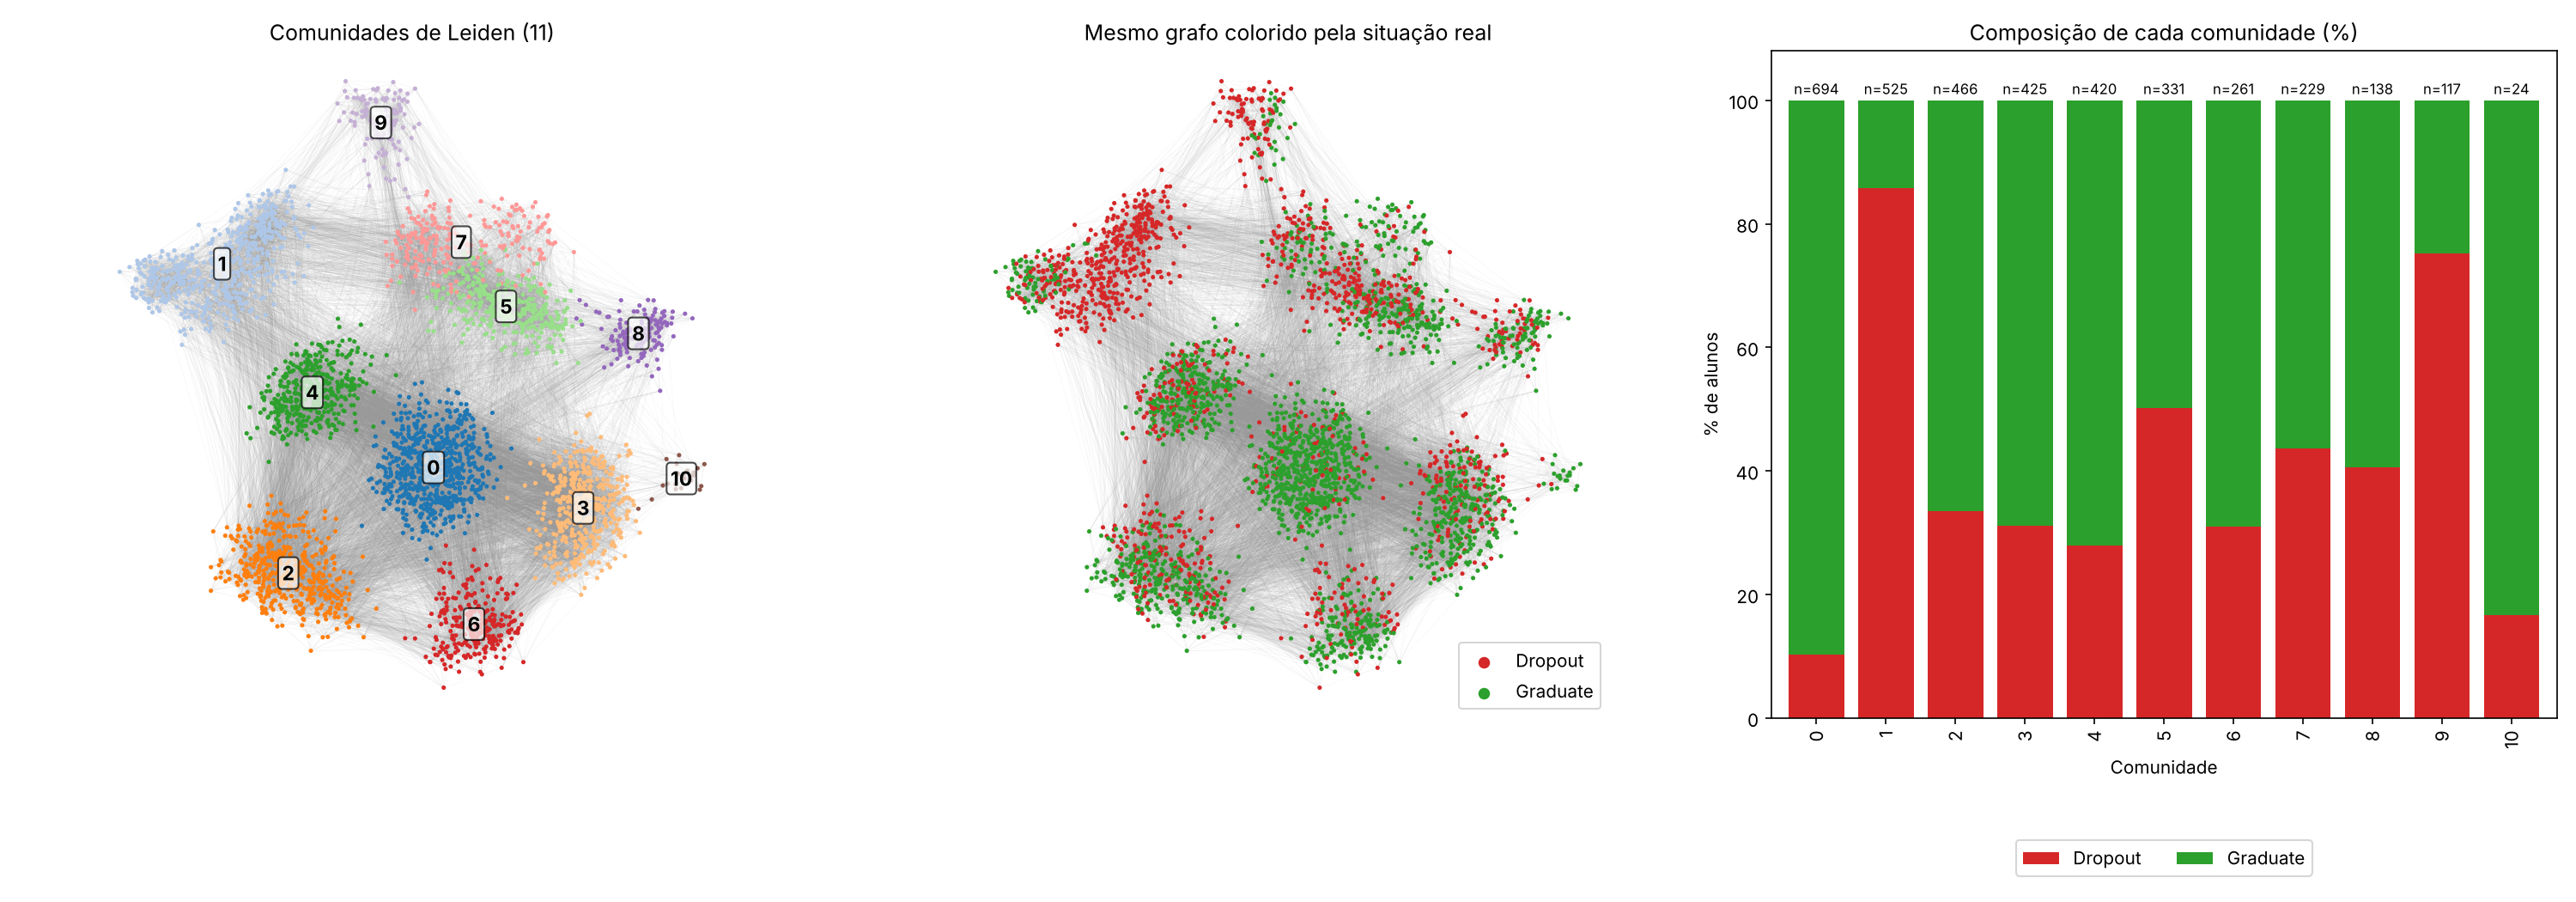

In [ ]:
display(Image(f"{PASTA_SAIDA}/leiden_comunidades.png"))

In [ ]:
res_leiden["tabela"]

,Dropout,Graduate,tamanho
comunidade,,,
0,71,623,694
1,450,75,525
2,156,310,466
3,132,293,425
4,117,303,420
5,166,165,331
6,81,180,261
7,100,129,229
8,56,82,138


> **Como ler:** à esquerda, as comunidades; no meio, o mesmo grafo colorido pela situação real; à direita, a % de Dropout/Graduate em cada comunidade. O Leiden agrupa por *similaridade geral* (não olha o rótulo), por isso ARI/NMI baixos são esperados, mas várias comunidades ficam bem polarizadas.

## 3. GNN + Associação

A GNN treina com 80% dos alunos (10% disso vira validação para o *early stopping*) e é testada nos **20% cujo rótulo ficou escondido**. Depois, o Apriori busca perfis de alunos associados a cada classe prevista.

### Funções

In [ ]:
COLUNAS_ASSOCIACAO = [  # colunas interpretáveis usadas nas regras
    "Debtor", "Tuition fees up to date", "Scholarship holder", "Gender",
    "Displaced", "Age at enrollment", "Admission grade",
    "Previous qualification (grade)",
    "Curricular units 1st sem (approved)", "Curricular units 1st sem (grade)",
    "Curricular units 2nd sem (approved)", "Curricular units 2nd sem (grade)",
    "Curricular units 2nd sem (evaluations)",
]
CONVS = {"gcn": GCNConv, "sage": SAGEConv}

#### 1. Dados e grafo

In [37]:
def preparar_features(df, alvo="Target"):
    """One-hot nas categóricas + padronização nas numéricas."""
    X = df.drop(columns=[alvo])
    cats = [c for c in X.columns if c in COLUNAS_CATEGORICAS]
    nums = [c for c in X.columns if c not in COLUNAS_CATEGORICAS]
    X_num = pd.DataFrame(StandardScaler().fit_transform(X[nums]), columns=nums, index=X.index)
    X_cat = pd.get_dummies(X[cats].astype(str), dtype=float)
    return pd.concat([X_num, X_cat], axis=1).values.astype(np.float32)


def construir_data(df, dist, alvo="Target", k=15, seed=42, frac_teste=0.2, frac_val=0.1):
    """Grafo + divisão estratificada: 80% treino (10% disso vira validação) / 20% teste."""
    classes = sorted(df[alvo].unique())
    y = df[alvo].map({c: i for i, c in enumerate(classes)}).values

    g = construir_grafo_knn(dist, k=k)
    arestas = np.array(g.get_edgelist())
    pesos = np.array(g.es["weight"], dtype=np.float32)
    edge_index = np.concatenate([arestas, arestas[:, ::-1]]).T  # ida e volta
    edge_weight = np.concatenate([pesos, pesos])

    idx_trein, idx_teste = train_test_split(np.arange(len(df)), test_size=frac_teste,
                                           stratify=y, random_state=seed)
    idx_trein, idx_val = train_test_split(idx_trein, test_size=frac_val,
                                          stratify=y[idx_trein], random_state=seed)

    def mascara(ids):
        m = torch.zeros(len(df), dtype=torch.bool)
        m[ids] = True
        return m

    data = Data(x=torch.tensor(preparar_features(df, alvo)),
                edge_index=torch.tensor(edge_index, dtype=torch.long),
                edge_weight=torch.tensor(edge_weight),
                y=torch.tensor(y, dtype=torch.long),
                train_mask=mascara(idx_trein), val_mask=mascara(idx_val),
                test_mask=mascara(idx_teste))
    return data, classes

#### 2. Modelo, treino e avaliação

In [38]:
class GNN(torch.nn.Module):
    """2 camadas. GCN usa o peso das arestas; GraphSAGE mantém as características
    do próprio aluno separadas das dos vizinhos."""

    def __init__(self, arquitetura, in_dim, hidden, out_dim, dropout=0.5):
        super().__init__()
        conv = CONVS[arquitetura]
        self.conv1, self.conv2 = conv(in_dim, hidden), conv(hidden, out_dim)
        self.usa_peso = arquitetura == "gcn"
        self.dropout = dropout

    def forward(self, data):
        arestas = (data.edge_index, data.edge_weight) if self.usa_peso else (data.edge_index,)
        x = F.dropout(data.x, self.dropout, self.training)
        x = F.relu(self.conv1(x, *arestas))
        x = F.dropout(x, self.dropout, self.training)
        return self.conv2(x, *arestas)  # logits


def treinar_gnn(data, n_classes, arquitetura="sage", epocas=300, lr=0.01, hidden=32,
                weight_decay=5e-4, paciencia=50, device="cpu", verbose=True):
    model = GNN(arquitetura, data.num_node_features, hidden, n_classes).to(device)
    data = data.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)

    cont = torch.bincount(data.y[data.train_mask], minlength=n_classes).float()
    pesos = (cont.sum() / (n_classes * cont)).to(device)  # compensa desbalanceamento

    def perda(out, mask):
        return F.cross_entropy(out[mask], data.y[mask], weight=pesos)

    hist = {"loss_treino": [], "loss_val": [], "acc_val": []}
    melhor_loss, melhor_estado, sem_melhora = float("inf"), None, 0

    for ep in range(epocas):
        model.train()
        opt.zero_grad()
        loss = perda(model(data), data.train_mask)
        loss.backward()
        opt.step()

        model.eval()
        with torch.no_grad():
            out = model(data)
            loss_val = perda(out, data.val_mask).item()
            acc_val = (out[data.val_mask].argmax(1) == data.y[data.val_mask]).float().mean().item()
        hist["loss_treino"].append(loss.item())
        hist["loss_val"].append(loss_val)
        hist["acc_val"].append(acc_val)

        if loss_val < melhor_loss:
            melhor_loss, melhor_estado, sem_melhora = loss_val, copy.deepcopy(model.state_dict()), 0
        else:
            sem_melhora += 1
            if sem_melhora >= paciencia:
                if verbose:
                    print(f"[GNN+Associação] Early stopping na época {ep + 1}")
                break
        if verbose and (ep + 1) % 50 == 0:
            print(f"[GNN+Associação] Época {ep + 1:03d} | loss treino {loss.item():.4f} "
                  f"| loss val {loss_val:.4f} | acc val {acc_val:.4f}")

    model.load_state_dict(melhor_estado)
    return model, hist


def prever(model, data, device="cpu"):
    model.eval()
    with torch.no_grad():
        prob = F.softmax(model(data.to(device)), dim=1).cpu().numpy()
    return prob.argmax(1), prob


def calcular_metricas(y, pred, prob, classes):
    """Acurácia, F1, recall/precisão por classe (+ AUC se binário) e matriz de confusão."""
    cm = confusion_matrix(y, pred)
    rec, prec = cm.diagonal() / cm.sum(axis=1), cm.diagonal() / cm.sum(axis=0)
    m = {"acuracia": float((pred == y).mean()), "f1_macro": f1_score(y, pred, average="macro")}
    for i, c in enumerate(classes):
        m[f"recall_{c}"], m[f"precisao_{c}"] = rec[i], prec[i]
    if len(classes) == 2:
        m["auc"] = roc_auc_score(y, prob[:, 1])
    return m, cm


def plotar_resultados(hist, cm, classes, metricas, caminho_png):
    fig, axs = plt.subplots(1, 3, figsize=(17, 4.8))
    axs[0].plot(hist["loss_treino"], label="treino")
    axs[0].plot(hist["loss_val"], label="validação")
    axs[0].set(title="Loss por época", xlabel="época")
    axs[0].legend()
    axs[1].plot(hist["acc_val"], color="tab:green")
    axs[1].set(title="Acurácia de validação", xlabel="época")
    ConfusionMatrixDisplay(cm, display_labels=classes).plot(ax=axs[2], cmap="Blues", colorbar=False)
    titulo = " | ".join(f"{k}={metricas[k]:.3f}" for k in ("acuracia", "f1_macro", "auc") if k in metricas)
    axs[2].set_title(f"Matriz de confusão (teste)\n{titulo}", fontsize=10)
    plt.tight_layout()
    fig.savefig(caminho_png, dpi=150)
    plt.close(fig)

#### 3. Regras de associação

In [39]:
def _construir_itens(df, colunas, rotulo_pred):
    """Cada aluno vira uma 'cesta' de itens (atributo=faixa/valor) + a classe prevista."""
    itens = {}
    for c in colunas:
        s = df[c]
        if s.nunique() <= 2:
            for v in sorted(s.unique()):
                itens[f"{c}={int(v)}"] = (s == v).values
        else:
            faixas = pd.qcut(s, q=3, duplicates="drop")
            for iv in faixas.cat.categories:
                itens[f"{c} em [{iv.left:.1f}; {iv.right:.1f}]"] = (faixas == iv).values
    for cl in np.unique(rotulo_pred):
        itens[f"GNN={cl}"] = rotulo_pred == cl
    return pd.DataFrame(itens, index=df.index)


def minerar_associacoes(df, rotulo_pred, rotulo_real, min_support=0.05, min_conf=0.6, max_len=3):
    """Regras {perfil} -> {GNN=classe}, com a confiança também medida no rótulo real."""
    colunas = [c for c in COLUNAS_ASSOCIACAO if c in df.columns]
    base = _construir_itens(df, colunas, np.asarray(rotulo_pred))
    freq = apriori(base, min_support=min_support, use_colnames=True, max_len=max_len)
    regras = association_rules(freq, num_itemsets=len(base), metric="confidence",
                               min_threshold=min_conf)

    so_classe_no_fim = regras.apply(
        lambda r: len(r["consequents"]) == 1 and next(iter(r["consequents"])).startswith("GNN=")
        and not any(i.startswith("GNN=") for i in r["antecedents"]), axis=1)
    regras = regras[so_classe_no_fim].copy()

    regras["classe"] = regras["consequents"].apply(lambda s: next(iter(s)).replace("GNN=", ""))
    real = np.asarray(rotulo_real)
    regras["confianca_real"] = [
        float((real[base[list(ant)].all(axis=1).values] == cl).mean())
        for ant, cl in zip(regras["antecedents"], regras["classe"])]
    regras["perfil"] = regras["antecedents"].apply(lambda s: " E ".join(sorted(s)))
    cols = ["perfil", "classe", "support", "confidence", "lift", "confianca_real"]
    return regras[cols].sort_values(["classe", "lift"], ascending=[True, False]).reset_index(drop=True)


def plotar_regras(regras, classes, caminho_png, top=8):
    fig, axs = plt.subplots(len(classes), 1, figsize=(13, 4.2 * len(classes)))
    for ax, cl in zip(np.atleast_1d(axs), classes):
        sub = regras[regras["classe"] == cl].head(top)[::-1]
        if sub.empty:
            ax.set_title(f"Nenhuma regra encontrada para {cl}")
            ax.axis("off")
            continue
        ax.barh([p if len(p) < 85 else p[:82] + "..." for p in sub["perfil"]],
                sub["lift"], color=CORES_ALVO.get(cl, "gray"))
        for i, (lift, conf) in enumerate(zip(sub["lift"], sub["confidence"])):
            ax.text(lift, i, f"  lift {lift:.2f} | conf {conf:.0%}", va="center", fontsize=8)
        ax.set_xlim(0, sub["lift"].max() * 1.35)
        ax.set_title(f"Perfis mais associados a: {cl} (previsto pela GNN)")
        ax.axvline(1, color="k", ls="--", lw=0.8)
        ax.tick_params(axis="y", labelsize=8)
    plt.tight_layout()
    fig.savefig(caminho_png, dpi=150)
    plt.close(fig)

#### 4. Pipeline GNN + Associação (uma divisão 80/20)

In [40]:
def executar_gnn(df, dist, pasta_saida="resultados", alvo="Target", k=15, seed=42,
             min_support=0.05, min_conf=0.6, arquitetura="sage"):
    os.makedirs(pasta_saida, exist_ok=True)
    torch.manual_seed(seed)
    device = "cuda" if torch.cuda.is_available() else "cpu"

    data, classes = construir_data(df, dist, alvo, k=k, seed=seed)
    y, te = data.y.numpy(), data.test_mask.numpy()
    print(f"[GNN+Associação] Nós: {data.num_nodes} | Arestas: {data.edge_index.shape[1] // 2} "
          f"| Treino: {int(data.train_mask.sum())} | Val: {int(data.val_mask.sum())} "
          f"| Teste: {int(te.sum())}")

    print(f"[GNN+Associação] Treinando {arquitetura.upper()} (o rótulo do teste fica escondido)...")
    model, hist = treinar_gnn(data, len(classes), arquitetura, device=device)
    pred, prob = prever(model, data, device)
    metricas, cm = calcular_metricas(y[te], pred[te], prob[te], classes)

    print("\n=== Resultados GNN (conjunto de teste) ===")
    print(classification_report(y[te], pred[te], target_names=classes, digits=3))
    print({k_: round(v, 4) for k_, v in metricas.items() if k_ in ("acuracia", "f1_macro", "auc")})

    acertos = pred[te] == y[te]
    print(f"\n>>> TAXA DE ACERTO NO TESTE (20% escondidos): {acertos.mean():.1%}  "
          f"({int(acertos.sum())} de {int(te.sum())} alunos)")
    for i, c in enumerate(classes):
        sel = y[te] == i
        print(f"    Dos que realmente eram {c}: acertou {acertos[sel].mean():.1%} "
              f"({int(acertos[sel].sum())} de {int(sel.sum())})")
    pd.DataFrame({"aluno": np.where(te)[0], "real": np.array(classes)[y[te]],
                  "previsto": np.array(classes)[pred[te]],
                  f"prob_{classes[0]}": prob[te, 0].round(3), "acertou": acertos}
                 ).to_csv(os.path.join(pasta_saida, "gnn_predicoes_teste.csv"), index=False)
    png1 = os.path.join(pasta_saida, "gnn_resultados.png")
    plotar_resultados(hist, cm, classes, metricas, png1)

    print("\n[GNN+Associação] Minerando regras de associação sobre as predições da GNN...")
    regras = minerar_associacoes(df, np.array(classes)[pred], df[alvo].values,
                                 min_support=min_support, min_conf=min_conf)
    print(f"[GNN+Associação] {len(regras)} regras encontradas")
    if len(regras):
        pd.set_option("display.width", 200, "display.max_colwidth", 90)
        print(regras.groupby("classe").head(5).round(3).to_string(index=False))
    regras.to_csv(os.path.join(pasta_saida, "gnn_regras_associacao.csv"), index=False)
    png2 = os.path.join(pasta_saida, "gnn_regras_associacao.png")
    plotar_regras(regras, classes, png2)
    print(f"[GNN+Associação] Figuras salvas em: {png1} e {png2}")
    return {"metricas": metricas, "regras": regras, "classes": classes}

### Executar GNN + Associação (um 80/20)

In [41]:
res_gnn = executar_gnn(df, dist, PASTA_SAIDA, k=K, seed=SEED, arquitetura=ARQUITETURA)

[GNN+Associação] Nós: 3630 | Arestas: 40660 | Treino: 2613 | Val: 291 | Teste: 726
[GNN+Associação] Treinando SAGE (o rótulo do teste fica escondido)...
[GNN+Associação] Época 050 | loss treino 0.2954 | loss val 0.3328 | acc val 0.8832
[GNN+Associação] Época 100 | loss treino 0.2697 | loss val 0.3357 | acc val 0.8797
[GNN+Associação] Early stopping na época 138

=== Resultados GNN (conjunto de teste) ===
              precision    recall  f1-score   support

     Dropout      0.896     0.817     0.855       284
    Graduate      0.889     0.939     0.913       442

    accuracy                          0.891       726
   macro avg      0.892     0.878     0.884       726
weighted avg      0.891     0.891     0.890       726

{'acuracia': 0.8912, 'f1_macro': 0.8838, 'auc': 0.9434}

>>> TAXA DE ACERTO NO TESTE (20% escondidos): 89.1%  (647 de 726 alunos)
    Dos que realmente eram Dropout: acertou 81.7% (232 de 284)
    Dos que realmente eram Graduate: acertou 93.9% (415 de 442)

[GNN+As

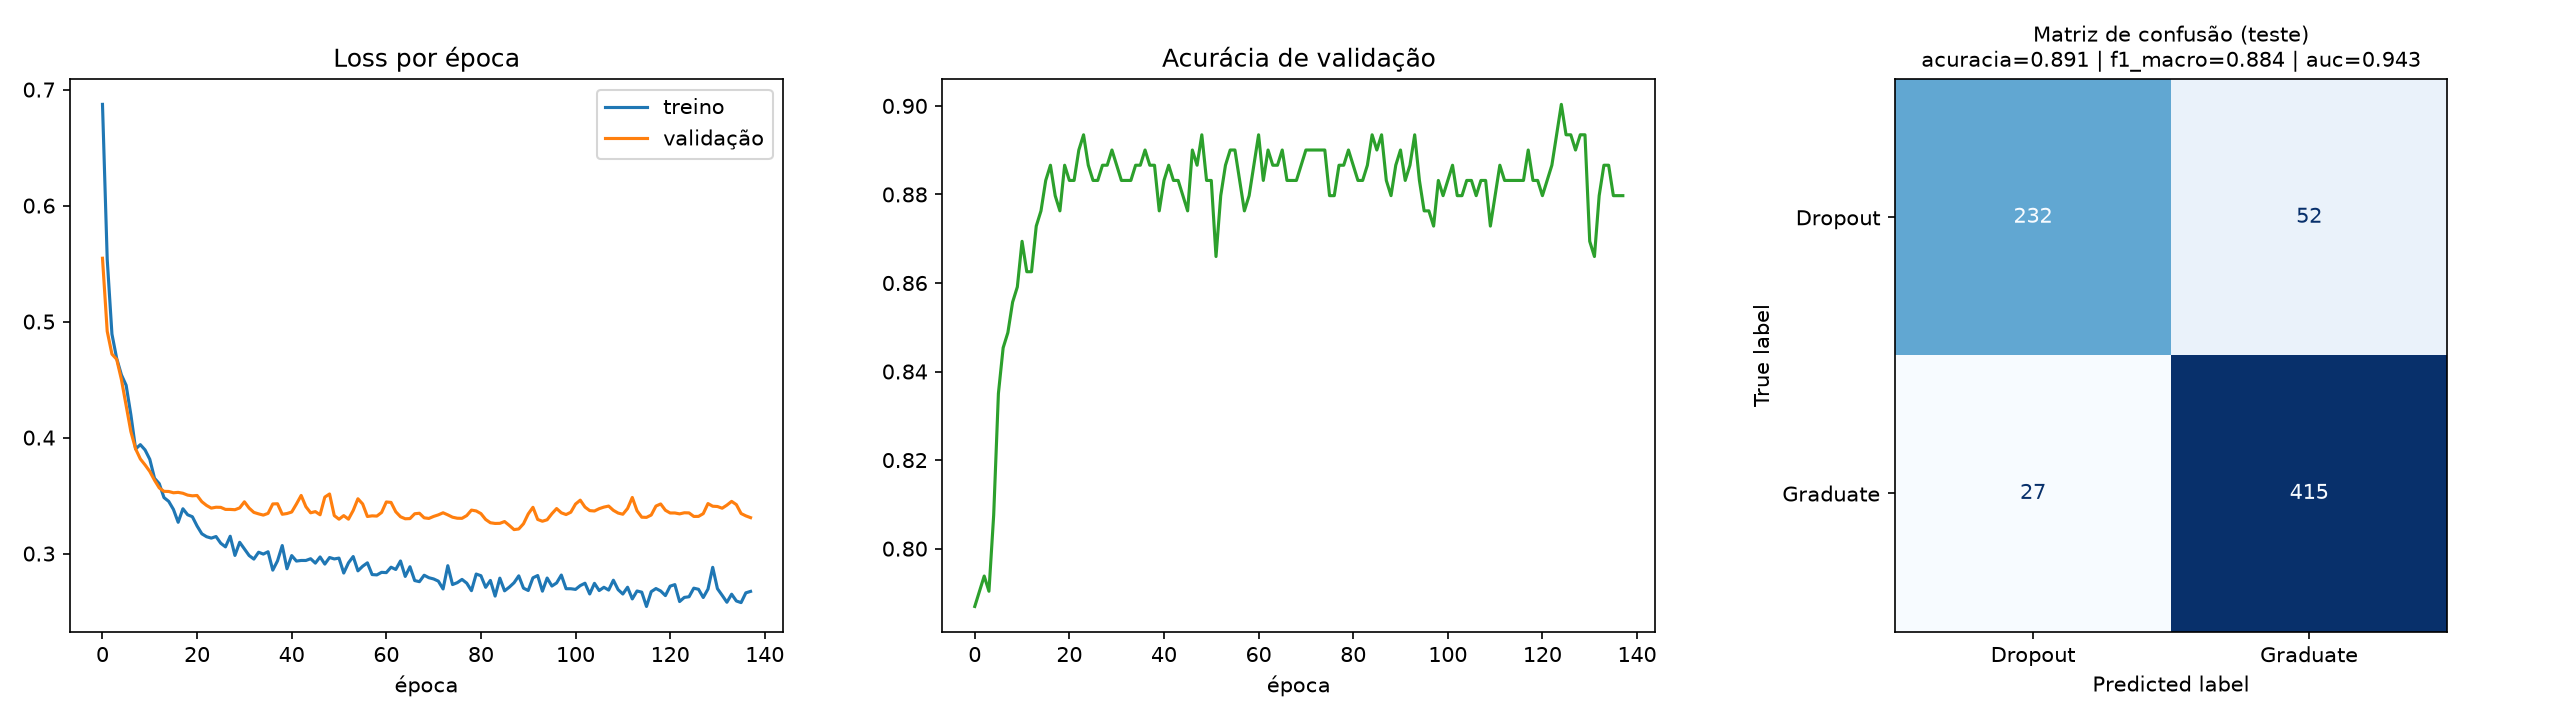

In [42]:
display(Image(f"{PASTA_SAIDA}/gnn_resultados.png"))

**Previsão aluno a aluno nos 20% de teste** (real × previsto):

In [43]:
pd.read_csv(f"{PASTA_SAIDA}/gnn_predicoes_teste.csv").head(15)

,aluno,real,previsto,prob_Dropout,acertou
0,2,Dropout,Dropout,0.999,True
1,3,Graduate,Graduate,0.326,True
2,4,Graduate,Graduate,0.061,True
3,10,Graduate,Graduate,0.087,True
4,13,Graduate,Graduate,0.129,True
5,16,Graduate,Graduate,0.040,True
6,19,Graduate,Graduate,0.051,True
7,26,Graduate,Dropout,0.582,False
8,29,Dropout,Dropout,0.930,True
9,30,Graduate,Graduate,0.160,True


**Regras de associação** (top 8 por classe; `confianca_real` = a mesma regra medida no rótulo verdadeiro):

In [44]:
res_gnn["regras"].groupby("classe").head(8).round(3)

,perfil,classe,support,confidence,lift,confianca_real
0,Age at enrollment em [22.0; 70.0] E Tuition fees up to date=0,Dropout,0.078,0.990,2.721,0.983
1,Admission grade em [95.0; 120.2] E Tuition fees up to date=0,Dropout,0.058,0.986,2.712,0.977
2,Curricular units 1st sem (approved) em [-0.0; 4.0] E Tuition fees up to date=0,Dropout,0.099,0.984,2.705,0.989
3,Curricular units 2nd sem (approved) em [-0.0; 4.0] E Tuition fees up to date=0,Dropout,0.109,0.980,2.695,0.988
4,Curricular units 2nd sem (grade) em [-0.0; 11.4] E Tuition fees up to date=0,Dropout,0.093,0.980,2.694,0.980
5,Previous qualification (grade) em [129.7; 137.0] E Tuition fees up to date=0,Dropout,0.051,0.979,2.692,0.963
6,Curricular units 1st sem (grade) em [-0.0; 11.6] E Tuition fees up to date=0,Dropout,0.083,0.974,2.679,0.971
7,Displaced=0 E Tuition fees up to date=0,Dropout,0.076,0.972,2.673,0.968
123,Age at enrollment em [17.0; 19.0] E Curricular units 2nd sem (approved) em [6.0; 20.0],Graduate,0.109,0.997,1.567,0.952
124,Curricular units 2nd sem (approved) em [6.0; 20.0] E Scholarship holder=1,Graduate,0.076,0.996,1.566,0.975


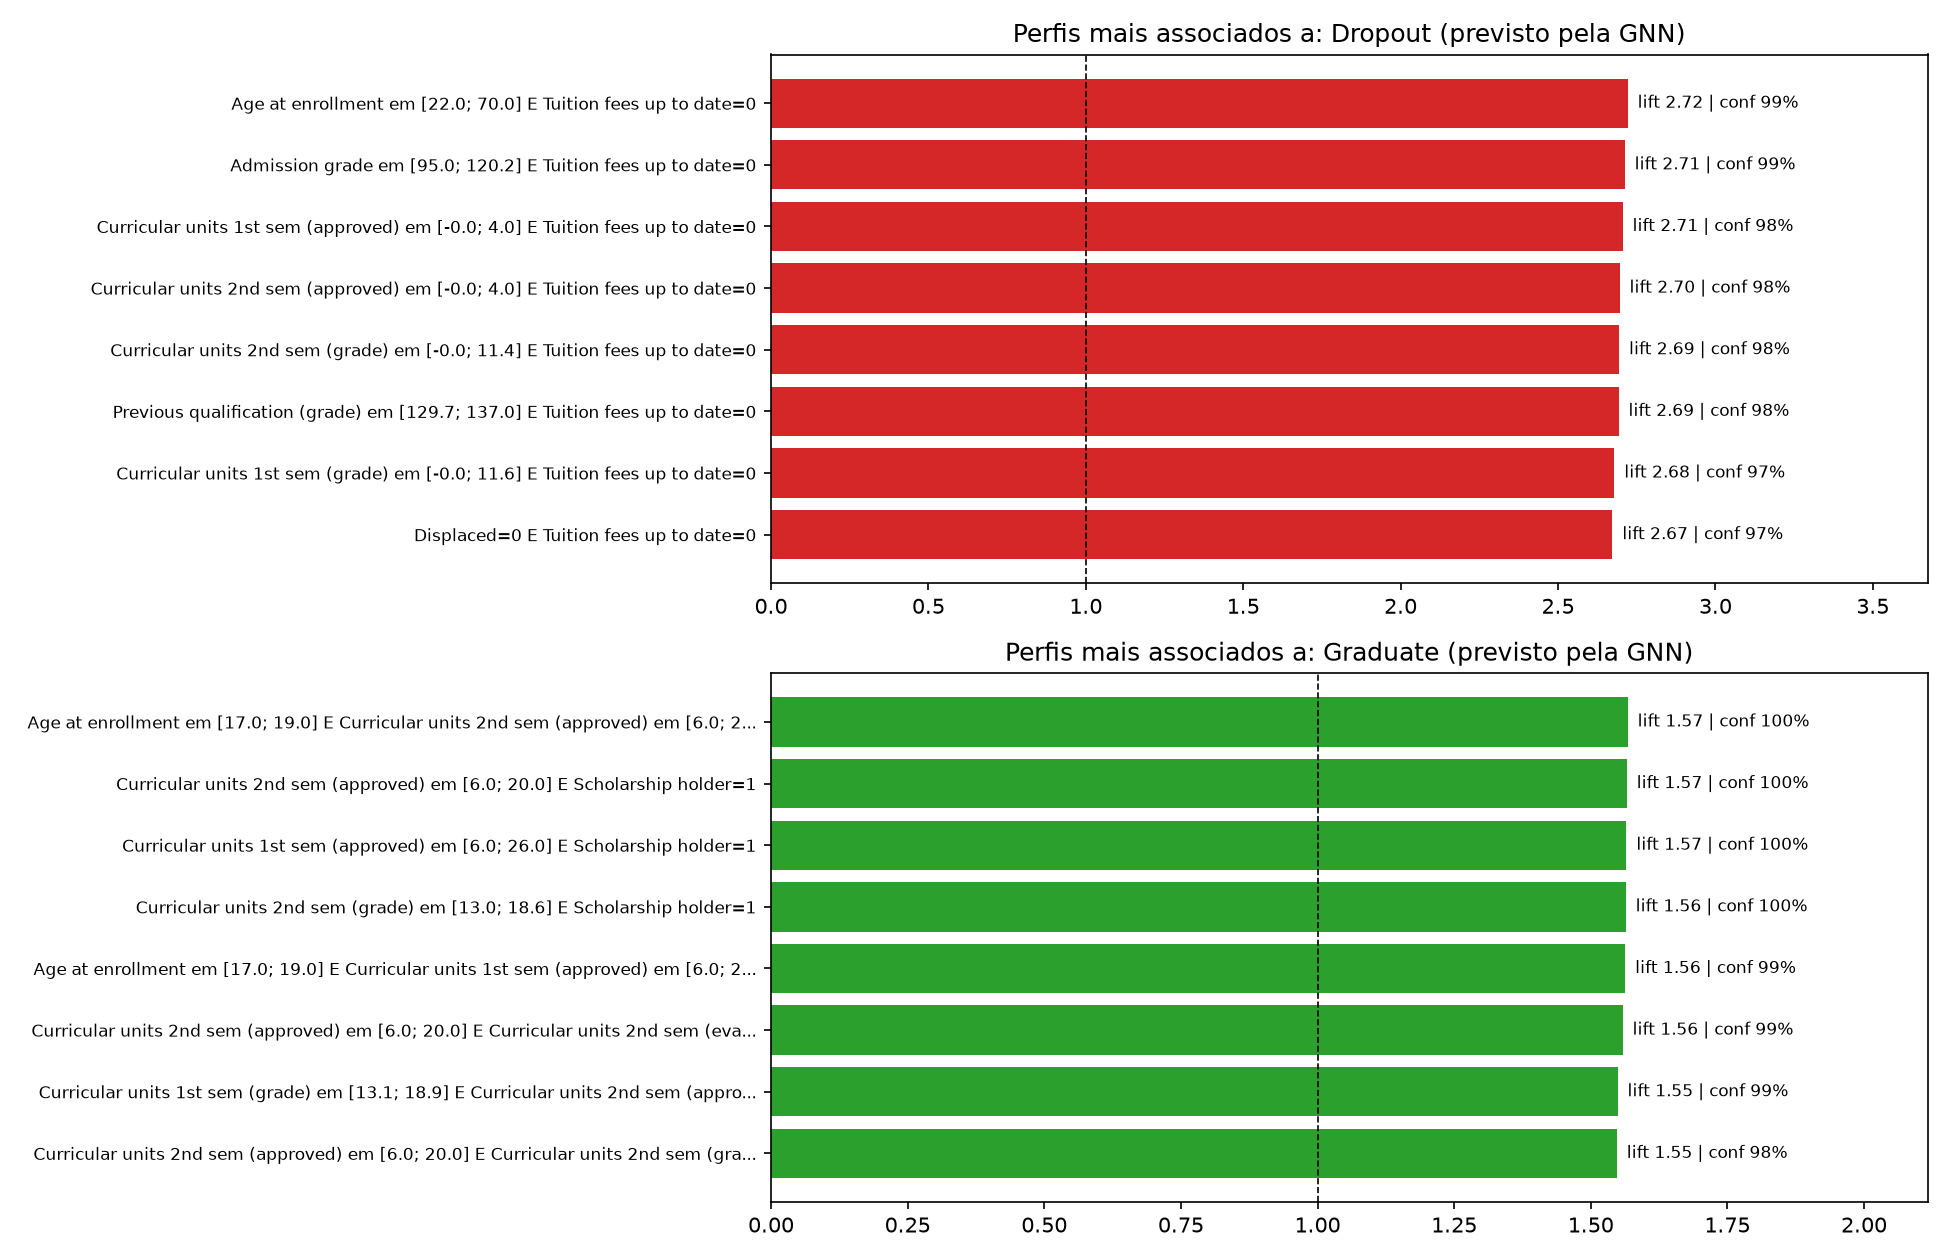

In [45]:
display(Image(f"{PASTA_SAIDA}/gnn_regras_associacao.png"))

## 4. Teste 80/20 repetido

Uma única divisão pode dar sorte ou azar. Aqui o 80/20 é repetido `REPETICOES` vezes com sorteios diferentes, comparando a **GCN**, o **GraphSAGE** e uma **regressão logística** (mesmas características, mas *sem grafo*), que serve de referência para saber se o grafo realmente ajuda.

> Leva alguns minutos com 10 repetições; use `REPETICOES = 3` para um teste rápido.

#### 5. Teste 80/20 repetido (GCN x GraphSAGE x regressão logística)

In [46]:
def teste_80_20(df, dist, pasta_saida="resultados", alvo="Target", n_repeticoes=10,
                k=15, seed_base=0):
    os.makedirs(pasta_saida, exist_ok=True)
    device = "cuda" if torch.cuda.is_available() else "cpu"
    nomes = ["GCN", "GraphSAGE", "Regressão logística"]
    linhas, cms = [], {n: 0 for n in nomes}

    for r in range(n_repeticoes):
        seed = seed_base + r
        data, classes = construir_data(df, dist, alvo, k=k, seed=seed)
        x, y = data.x.numpy(), data.y.numpy()
        tr, te = (data.train_mask | data.val_mask).numpy(), data.test_mask.numpy()

        previsoes = {}
        for nome, arq in (("GCN", "gcn"), ("GraphSAGE", "sage")):
            torch.manual_seed(seed)
            model, _ = treinar_gnn(data, len(classes), arq, device=device, verbose=False)
            pred, prob = prever(model, data, device)
            previsoes[nome] = (pred[te], prob[te])
        lr = LogisticRegression(max_iter=2000, class_weight="balanced").fit(x[tr], y[tr])
        previsoes["Regressão logística"] = (lr.predict(x[te]), lr.predict_proba(x[te]))

        for nome, (p_, pr_) in previsoes.items():
            m, cm = calcular_metricas(y[te], p_, pr_, classes)
            cms[nome] = cms[nome] + cm
            linhas.append({"modelo": nome, "repeticao": r + 1, **m})
        print(f"[Teste 80/20] repetição {r + 1}/{n_repeticoes} | " + " | ".join(
            f"{l['modelo']}={l['acuracia']:.3f}" for l in linhas[-3:]))

    res = pd.DataFrame(linhas)
    metricas = [c for c in res.columns if c not in ("modelo", "repeticao")]
    print("\n=== Teste 80/20 repetido: taxa de acerto no que o modelo NÃO viu (média ± desvio) ===")
    for nome in nomes:
        print(f"\n{nome}")
        for m in metricas:
            v = res.loc[res.modelo == nome, m]
            print(f"  {m:>20}: {v.mean():.3f} ± {v.std():.3f}")
    res.to_csv(os.path.join(pasta_saida, "teste_80_20_detalhado.csv"), index=False)
    res.groupby("modelo")[metricas].agg(["mean", "std"]).to_csv(
        os.path.join(pasta_saida, "teste_80_20_resumo.csv"))

    png = os.path.join(pasta_saida, "teste_80_20.png")
    plotar_comparacao(res, cms, classes, png)
    png_tab = os.path.join(pasta_saida, "teste_80_20_tabela.png")
    plotar_tabela_resumo(res, png_tab)
    print(f"\n[Teste 80/20] Figuras salvas em: {png} e {png_tab}")
    return res


def plotar_comparacao(res, cms, classes, caminho_png):
    """Matrizes de confusão acumuladas (%) de cada modelo + boxplots por métrica."""
    nomes, n_rep = list(cms), int(res["repeticao"].max())
    fig, axs = plt.subplots(1, 4, figsize=(24, 5))
    for ax, nome in zip(axs[:3], nomes):
        cm_pct = cms[nome] / cms[nome].sum(axis=1, keepdims=True) * 100
        ConfusionMatrixDisplay(cm_pct, display_labels=classes).plot(
            ax=ax, cmap="Blues", colorbar=False, values_format=".1f")
        ax.set_title(f"{nome}\n% de acerto por classe real ({n_rep} repetições)")

    cols = ["acuracia", f"recall_{classes[0]}", f"recall_{classes[-1]}"]
    cores, larg = ["#4c78a8", "#54a24b", "#f58518"], 0.26
    for i, nome in enumerate(nomes):
        axs[3].boxplot([res.loc[res.modelo == nome, c] for c in cols],
                       positions=np.arange(len(cols)) + (i - 1) * larg, widths=larg * 0.9,
                       patch_artist=True, boxprops=dict(facecolor=cores[i]),
                       medianprops=dict(color="k"))
        axs[3].plot([], [], color=cores[i], label=nome, lw=8)
    axs[3].set_xticks(range(len(cols)))
    axs[3].set_xticklabels(cols)
    axs[3].set_title(f"Variação nas {n_rep} divisões 80/20")
    axs[3].legend(loc="lower right")
    plt.tight_layout()
    fig.savefig(caminho_png, dpi=150)
    plt.close(fig)


def plotar_tabela_resumo(res, caminho_png):
    """Tabela-resumo do teste 80/20 repetido (média ± desvio) em imagem."""
    nomes, n_rep = list(dict.fromkeys(res["modelo"])), int(res["repeticao"].max())
    cols = [("acuracia", "Acerto geral"), ("recall_Dropout", "Acerto em Dropout"),
            ("recall_Graduate", "Acerto em Graduate")]
    media = {m: [res.loc[res.modelo == m, c].mean() * 100 for c, _ in cols] for m in nomes}
    desvio = {m: [res.loc[res.modelo == m, c].std() * 100 for c, _ in cols] for m in nomes}
    melhor = [max(nomes, key=lambda m: media[m][j]) for j in range(len(cols))]

    fig, ax = plt.subplots(figsize=(11, 1.9 + 0.55 * len(nomes)))
    ax.axis("off")
    ax.set_title(f"Teste 80/20 repetido {n_rep} vezes (taxa de acerto em alunos não vistos)",
                 fontsize=13, weight="bold", pad=8)
    texto = [[m] + [f"{media[m][j]:.1f}%" + (f" ± {desvio[m][j]:.1f}" if j == 0 else "")
                    for j in range(len(cols))] for m in nomes]
    tab = ax.table(cellText=texto, colLabels=["Modelo"] + [t for _, t in cols],
                   cellLoc="center", loc="center")
    tab.auto_set_font_size(False)
    tab.set_fontsize(12)
    tab.scale(1, 2.3)

    for j, cor in enumerate(["#34495e", "#4c78a8", "#d62728", "#2ca02c"]):
        tab[0, j].set_facecolor(cor)
        tab[0, j].set_text_props(color="white", weight="bold")
    for i, m in enumerate(nomes, start=1):
        for j in range(4):
            c = tab[i, j]
            c.set_facecolor("#f4f6f8" if i % 2 else "white")
            c.set_edgecolor("#d0d4d9")
            if j == 0:
                c.set_text_props(weight="bold", ha="left")
                c._loc = "left"
            elif melhor[j - 1] == m:
                c.set_facecolor("#d5f0dc")
                c.set_text_props(weight="bold")
    tab.auto_set_column_width([0, 1, 2, 3])
    ax.text(0.5, -0.02, "Verde = melhor de cada coluna. ± = desvio-padrão do acerto geral "
            "entre as divisões.", ha="center", va="top", fontsize=9, color="#555555",
            transform=ax.transAxes)
    fig.savefig(caminho_png, dpi=150, bbox_inches="tight")
    plt.close(fig)

### Executar o teste repetido

In [ ]:
res_teste = teste_80_20(df, dist, PASTA_SAIDA, n_repeticoes=REPETICOES, k=K)

[Teste 80/20] repetição 1/10 | GCN=0.860 | GraphSAGE=0.894 | Regressão logística=0.910
[Teste 80/20] repetição 2/10 | GCN=0.850 | GraphSAGE=0.887 | Regressão logística=0.904
[Teste 80/20] repetição 3/10 | GCN=0.873 | GraphSAGE=0.912 | Regressão logística=0.921
[Teste 80/20] repetição 4/10 | GCN=0.872 | GraphSAGE=0.901 | Regressão logística=0.898


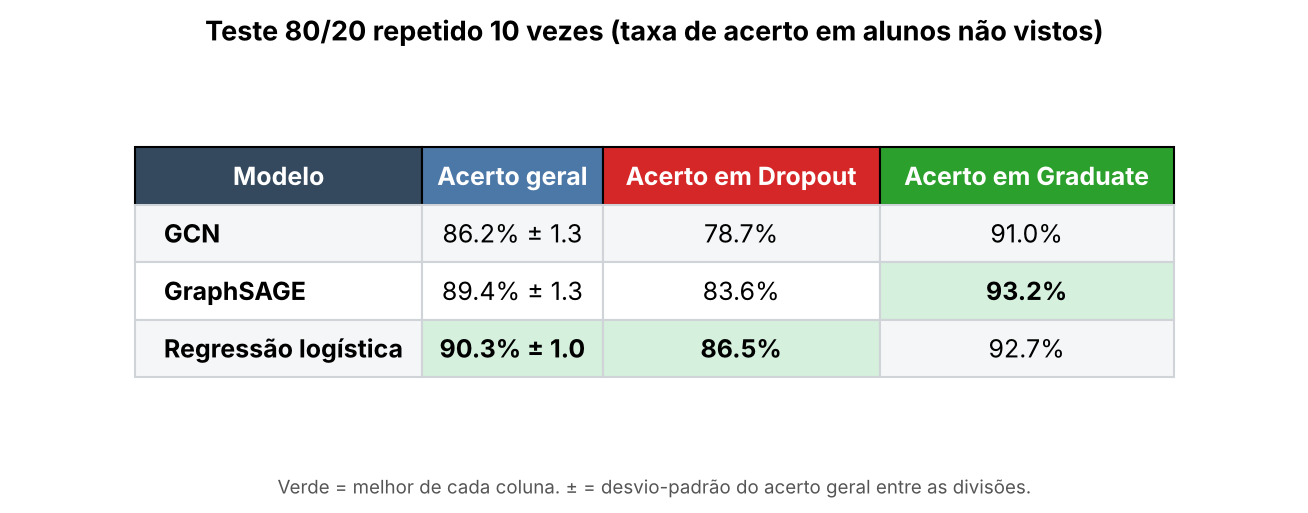

In [ ]:
display(Image(f"{PASTA_SAIDA}/teste_80_20_tabela.png"))

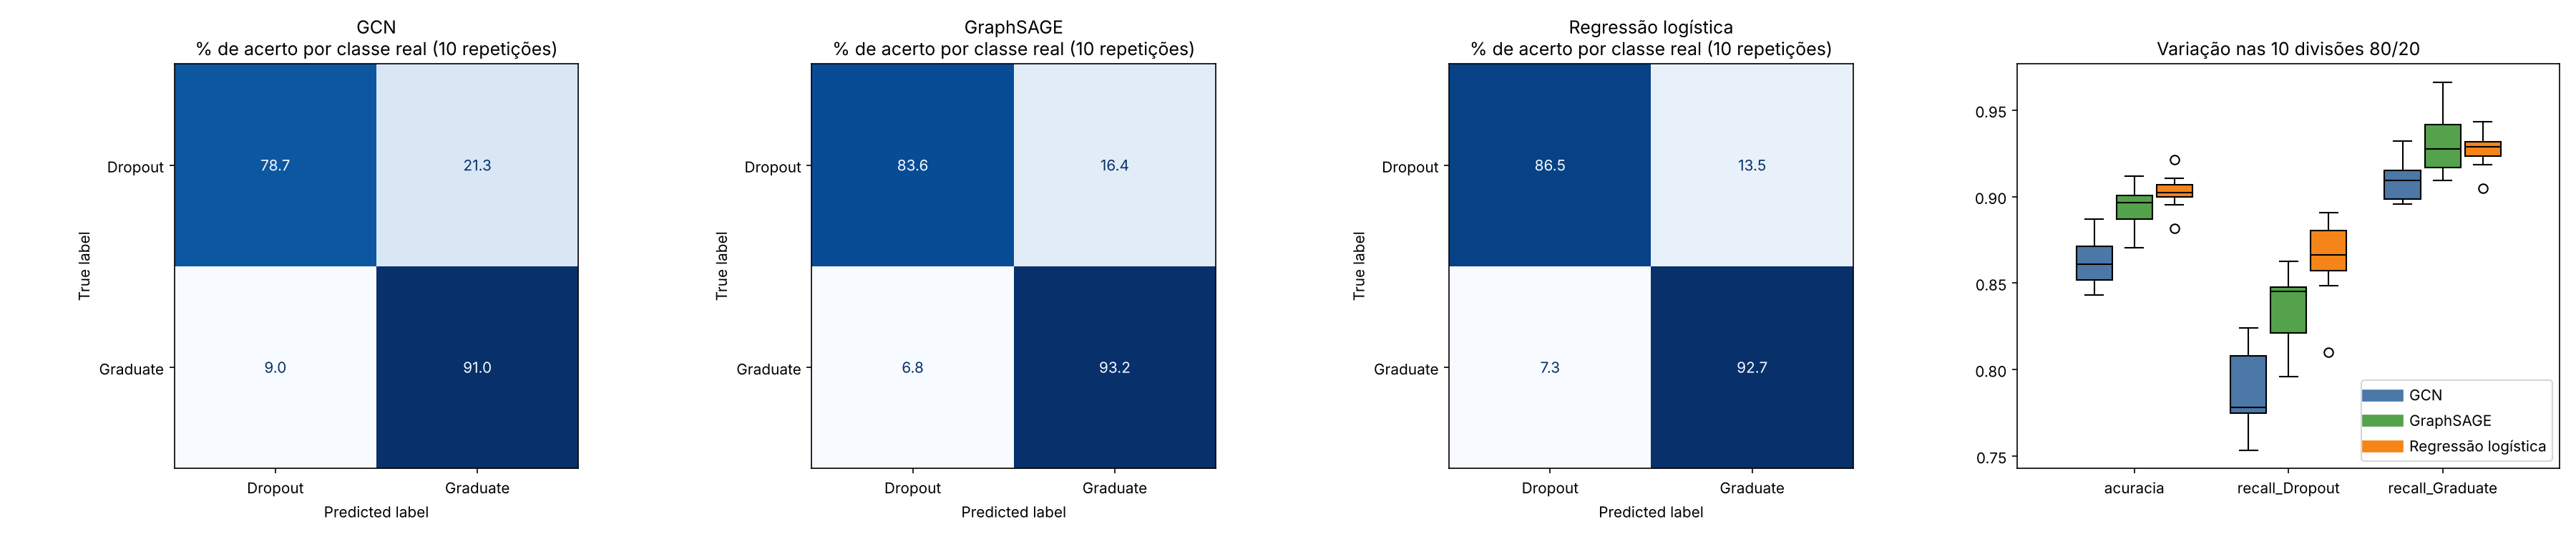

In [ ]:
display(Image(f"{PASTA_SAIDA}/teste_80_20.png"))

## 5. Conclusões

- **Leiden:** as comunidades separam perfis de alunos; algumas têm evasão muito alta e outras muito baixa. ARI/NMI baixos são esperados (agrupamento não supervisionado).
- **GNN:** acerta cerca de **90%** dos alunos do teste (rótulo escondido), com mais acerto em Graduate do que em Dropout.
- **Regressão logística (sem grafo):** fica praticamente empatada com o GraphSAGE. Nos dados atuais, as características individuais já explicam quase tudo e o grafo de similaridade não traz muita informação nova. Conexões reais entre alunos (mesma turma, mesmo curso) poderiam mudar isso.
- **Regras de associação:** mensalidade em atraso e poucas disciplinas aprovadas aparecem associadas à evasão; muitas aprovações e notas altas, à aprovação.